In [ ]:
#switch methods to py file for easier handling of imports and functions
import cv2
import pytesseract
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'
print("OpenCV version:", cv2.__version__)
print("pytesseract version:", pytesseract.get_tesseract_version())
print("matplotlib version:", matplotlib.__version__)
print("numpy version:", np.__version__)


OpenCV version: 5.0.0
pytesseract version: 5.5.3.20260724
matplotlib version 3.11.2
numpy version 2.5.3


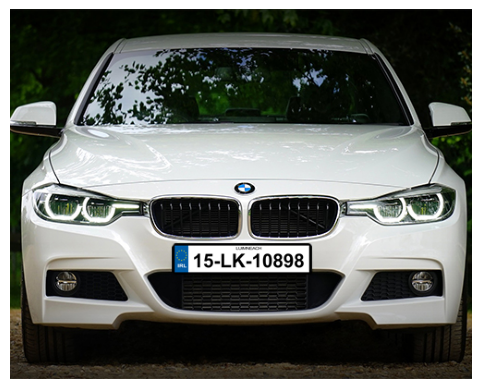

In [26]:
#Image check (test)
image = cv2.imread("car.png")
true_reading = "15LK10898"
plt.imshow(image)

#cropping
# x1, y1 = 200, 300
# x2, y2 = 400, 350

# plate = image[y1:y2, x1:x2]

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [27]:
# pass in BGR IMAGE not RGB IMAGE
def OCR_detection(image,show_detected_plate=False,show_cropped_plate=False):
    # STEP 1: Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # STEP 2: Reduce noise
    blurred = cv2.bilateralFilter(gray, 11, 17, 17)

    # STEP 3: Detect edges
    edges = cv2.Canny(blurred, 30, 200)

    # STEP 4: Find contours
    contours, _ = cv2.findContours(
        edges,
        cv2.RETR_LIST,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Sort contours by area
    contours = sorted(
        contours,
        key=cv2.contourArea,
        reverse=True
    )[:50]

    # STEP 5: Locate license plate
    plate_contour = None

    for contour in contours:
        perimeter = cv2.arcLength(contour, True)

        approx = cv2.approxPolyDP(
            contour, 0.02 * perimeter, True
        )

        # Look for rectangular contours
        if len(approx) == 4 and cv2.isContourConvex(approx):
            x, y, w, h = cv2.boundingRect(approx)

            aspect_ratio = w / h

            # Filter for license plate proportions
            if 2 < aspect_ratio < 6 and w > 60 and h > 15:
                plate_contour = (x, y, w, h)
                break

    # STEP 6: Crop detected plate
    if plate_contour is not None:
        x, y, w, h = plate_contour

        plate = image[y:y+h, x:x+w]

        # Draw rectangle around detected plate
        result = image.copy()
        cv2.rectangle(
            result,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            2
        )

        if (show_detected_plate):    
            plt.figure(figsize=(12, 5))
            plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
            plt.title("Detected License Plate")
            plt.axis("off")
            plt.show()

        # STEP 7: Prepare plate for OCR
        plate_gray = cv2.cvtColor(
            plate, cv2.COLOR_BGR2GRAY
        )

        plate_gray = cv2.resize(
            plate_gray,
            None,
            fx=2,
            fy=2,
            interpolation=cv2.INTER_CUBIC
        )

        _, thresh = cv2.threshold(
            plate_gray,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        # STEP 8: Read license plate
        config = "--psm 7 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"

        text = pytesseract.image_to_string(
            thresh,
            config=config
        )

        if (show_cropped_plate):
            plt.figure(figsize=(8, 3))
            plt.imshow(thresh, cmap="gray")
            plt.title("Cropped License Plate")
            plt.axis("off")
            plt.show()

        license_plate_text = text.strip()
        return(license_plate_text)

    else:
        return("No license plate detected.")


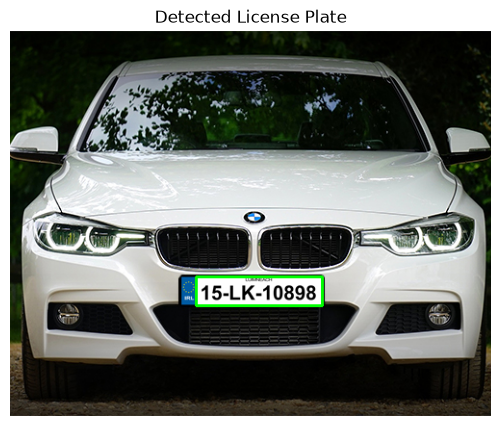

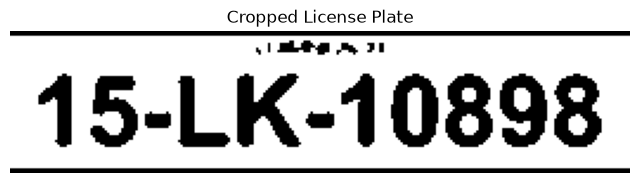

15LK10898


In [28]:
reading = OCR_detection(image, show_detected_plate=True, show_cropped_plate=True)
print(reading)

In [29]:
print("read from image = true reading?: " + str(reading == true_reading))

read from image = true reading?: True
